<a href="https://colab.research.google.com/github/nattaponm/Teach_Pysteps_KKN_summerStorm/blob/main/notebooks/03_motion_extrapolation_interpolation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 3: ทิศทางและความเร็วของพายุ — advection หรือ propagation?
### Optical flow, steering wind, Hovmöller diagrams, extrapolation and advection interpolation (15 → 5 min)

⏱️ เวลาเรียนโดยประมาณ **75–90 นาที** | ต้องผ่าน: Notebook 1–2

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **คำนวณ motion field** ด้วย Lucas–Kanade (LK), VET และ DARTS แล้วแปลงเป็นความเร็ว (km/h) และทิศทาง
2. **แยก "advection" กับ "propagation"** โดยเทียบการเคลื่อนที่ของพายุกับลมจาก sounding
3. **อ่าน Hovmöller diagram** เพื่อดูการเคลื่อนที่ของกลุ่มพายุตลอดบ่าย
4. **สร้าง extrapolation nowcast** และ **เพิ่มความละเอียดเวลา 15 → 5 นาที** ด้วย advection interpolation
5. (เสริม) **เห็นความแตกต่างระหว่าง "การเคลื่อนที่ของพายุ" กับ "ลมในพายุ"** จากข้อมูล Doppler

## 📖 1. แนวคิดและสมการ

### 1.1 Lagrangian persistence และ optical flow
สมมติว่ารูปแบบฝน $\Psi$ ถูกพัดพาไปโดยไม่เปลี่ยนรูป (Lagrangian persistence)
$$ \frac{\partial \Psi}{\partial t} + u\,\frac{\partial \Psi}{\partial x} + v\,\frac{\partial \Psi}{\partial y} = 0 $$
optical flow หา $\mathbf{u}=(u,v)$ ที่ทำให้ภาพเวลาก่อนหน้า "เลื่อน" ไปตรงกับภาพปัจจุบัน
- **LK:** หาความเร็วจากจุดเด่น (feature) ในหน้าต่างเล็ก แล้ว interpolate เป็นฟิลด์ (เร็ว)
- **VET:** หาฟิลด์ทั้งโดเมนที่เรียบและทำให้ภาพตรงกันมากที่สุด (ช้ากว่า)
- **DARTS:** แก้สมการใน Fourier domain จากหลายภาพ

### 1.2 จาก pixel/time step เป็น km/h
pysteps คืน motion field หน่วย **pixel ต่อ time step** ($\Delta x$ = 1 km, $\Delta t$ = 15 นาที)
$$ |\mathbf{V}|\ [\mathrm{km\,h^{-1}}] = \sqrt{u^2+v^2}\,\Delta x\,\frac{60}{\Delta t},\qquad
   \text{ทิศที่ไป} = \operatorname{atan2}(u,\,-v) $$
(ใช้ $-v$ เพราะแถวของ array เพิ่มขึ้นไปทางใต้)

### 1.3 Advection กับ propagation
กลุ่มพายุเคลื่อนที่ได้สองทาง: เซลล์ถูก **ลมพัดพา (advection)** และ **เซลล์ใหม่เกิดขึ้นที่ขอบด้านหนึ่ง** เช่นตามแนวอากาศเย็นที่ไหลออกจากพายุ (outflow/cold pool) เรียกว่า **propagation**
$$ \mathbf{V}_{\mathrm{system}} = \mathbf{V}_{\mathrm{advection}} + \mathbf{V}_{\mathrm{propagation}} $$
ลมเฉลี่ย 850–300 hPa ใช้แทน $\mathbf{V}_{\mathrm{advection}}$ ได้คร่าว ๆ (แนวคิดของ Corfidi) ถ้าพายุเคลื่อนที่ต่างจากลมมาก แปลว่า **propagation มีบทบาทมาก** และ nowcast ที่อาศัยแค่การเลื่อนภาพจะพลาดได้ง่าย

### 1.4 Advection interpolation
สร้างภาพระหว่างกลางด้วยการเลื่อนภาพก่อนหน้าไปข้างหน้า และภาพถัดไปถอยหลัง ($w=\tau/\Delta t$) แล้วเฉลี่ย **ในหน่วย Z เชิงเส้น**
$$ Z(t_0+\tau,\mathbf{x}) \approx (1-w)\,Z_0(\mathbf{x}-w\,\mathbf{u}) + w\,Z_1\big(\mathbf{x}+(1-w)\,\mathbf{u}\big) $$

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Pysteps_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 cartopy netCDF4 geopandas metpy cmweather arm_pyart
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "kkn_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.data_io import load_pcappi, time_index
from utils import mapplot as mp
from utils import kkn_tools as kt
from utils import sounding_tools as st
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Pysteps_KKN_summerStorm/data


In [2]:
from pysteps import motion
from pysteps.extrapolation.semilagrangian import extrapolate

Z, meta = load_pcappi(DATA)
ts = meta["timestamps"]
DT = meta["accutime"]                                   # 15 นาที
reports = kt.load_reports(DATA, meta)
date0 = ts[0].replace(hour=0, minute=0)

# ใช้พื้นที่ด้านตะวันตกเฉียงเหนือ (280 × 280 km) ที่มีพายุ เพื่อให้คำนวณเร็ว
BOX = kt.box_around(meta, 102.4, 17.3, 140)
Zc, mc = kt.crop(Z, meta, BOX)
Xin = kt.to_dbz_input(Zc)                               # NaN → −15 dBZ (optical flow ไม่รับ NaN)
storm = lambda i, thr=35: np.nan_to_num(Zc[i], nan=-15) >= thr
print(f"พื้นที่ศึกษา: {Zc.shape[1]}×{Zc.shape[2]} km | ช่วงเวลาที่ใช้: 05:00–14:00 UTC (12:00–21:00 น.)")

Pysteps configuration file found at: /usr/local/lib/python3.12/dist-packages/pysteps/pystepsrc



พื้นที่ศึกษา: 280×280 km | ช่วงเวลาที่ใช้: 05:00–14:00 UTC (12:00–21:00 น.)


## 🧭 3. Motion field ใน 3 ช่วงของวงจรชีวิตพายุ
ใช้ LK จาก 3 ภาพล่าสุด (30 นาที) ที่เวลา **06:45 UTC** (ก่อนเหตุที่ภูกระดึง), **09:15 UTC** (ก่อนเหตุที่หนองบัวลำภู) และ **12:00 UTC** (ระบบรวมตัว)

บันทึกรูปแล้ว: figures/nb3_motion_three_phases.png, figures/nb3_motion_three_phases.pdf


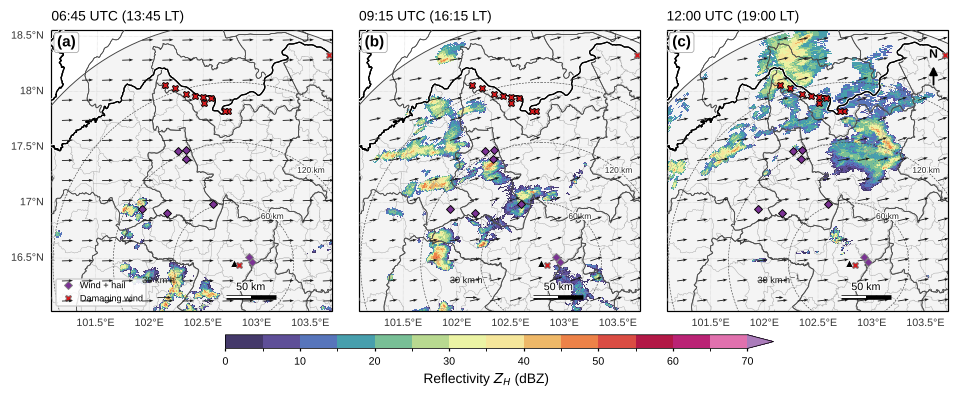

,time,speed_kmh,dir_to_deg,dir
0,06:45 UTC (13:45 LT),24.1,88.2,E
1,09:15 UTC (16:15 LT),25.4,77.0,ENE
2,12:00 UTC (19:00 LT),43.7,76.1,ENE


In [3]:
oflow = motion.get_method("LK")
times3 = ["06:45", "09:15", "12:00"]
fig, axs = mp.map_panels(1, 3, mc, panel_width=2.9)
rows = []
for k, (ax, hh) in enumerate(zip(axs, times3)):
    i = time_index(meta, hh)
    V = oflow(Xin[i - 2:i + 1], verbose=False)
    spd, ang = kt.speed_dir(V, storm(i))
    rows.append({"time": mp.tlabel(ts[i]), "speed_kmh": spd, "dir_to_deg": ang, "dir": kt.compass(ang)})
    im = mp.radar_map(ax, Zc[i], mc, title=mp.tlabel(ts[i]), north=(k == 2),
                      gridline_labels=("left", "bottom") if k == 0 else ("bottom",))
    mp.motion_arrows(ax, V, mc, step=20, key_kmh=30, timestep_min=DT, mask=mc["coverage"])
    mp.add_reports(ax, reports, legend=(k == 0), ms=4)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs)
mp.save_figure(fig, "nb3_motion_three_phases")
plt.show()
pd.DataFrame(rows).round(1)

### 3.1 เปรียบเทียบ LK, VET และ DARTS ที่เวลา 09:15 UTC

บันทึกรูปแล้ว: figures/nb3_motion_methods.png, figures/nb3_motion_methods.pdf


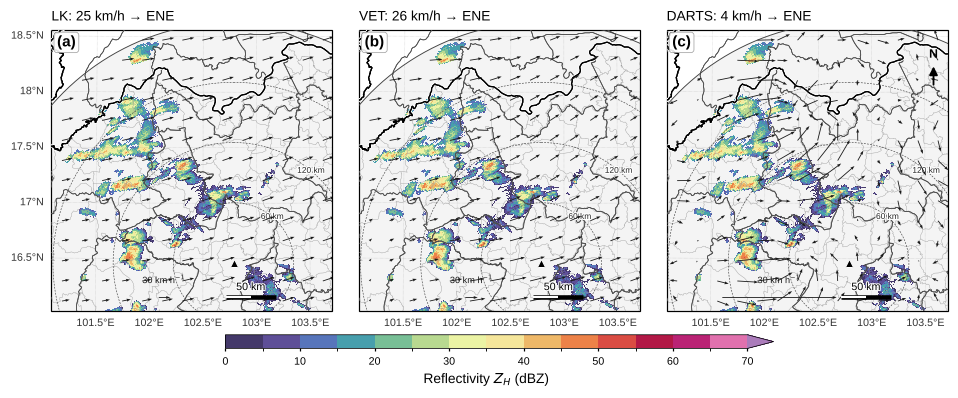

In [4]:
i = time_index(meta, "09:15")
fields = {"LK": oflow(Xin[i - 2:i + 1], verbose=False),
          "VET": motion.get_method("VET")(Xin[i - 2:i + 1], verbose=False),
          "DARTS": motion.get_method("DARTS")(Xin[i - 3:i + 1], N_t=2, verbose=False)}
fig, axs = mp.map_panels(1, 3, mc, panel_width=2.9)
for k, (ax, (name, V)) in enumerate(zip(axs, fields.items())):
    spd, ang = kt.speed_dir(V, storm(i))
    im = mp.radar_map(ax, Zc[i], mc, title=f"{name}: {spd:.0f} km/h → {kt.compass(ang)}", north=(k == 2),
                      gridline_labels=("left", "bottom") if k == 0 else ("bottom",))
    mp.motion_arrows(ax, V, mc, step=20, key_kmh=30, timestep_min=DT, mask=mc["coverage"])
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs)
mp.save_figure(fig, "nb3_motion_methods")
plt.show()

## 🌬️ 4. พายุเคลื่อนที่ไปทางเดียวกับลมหรือไม่?
เทียบ **การเคลื่อนที่ของพายุ (LK)** กับ **ลมเฉลี่ย 850–300 hPa** จาก sounding นครราชสีมา 07:00 น.

บันทึกรูปแล้ว: figures/nb3_propagation_vectors.png, figures/nb3_propagation_vectors.pdf


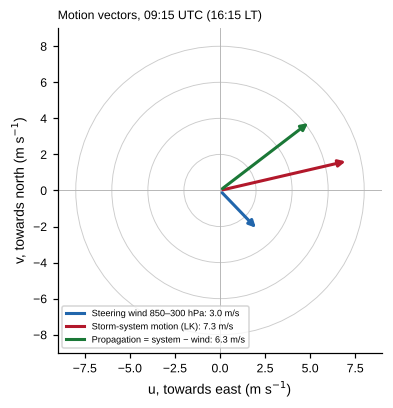

ลม 850–300 hPa: 11 km/h ไปทาง SE | พายุ: 26 km/h ไปทาง ENE


In [5]:
snd = st.load_sounding(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
u_env, v_env, spd_env, dir_env = st.layer_mean_wind(snd, 850, 300)
V = fields["LK"]
m = storm(i)
u_sys = np.mean(V[0][m]) * 1000 / (DT * 60)            # m/s ไปทางตะวันออก
v_sys = -np.mean(V[1][m]) * 1000 / (DT * 60)           # m/s ไปทางเหนือ (กลับทิศแถว)
u_prop, v_prop = u_sys - u_env, v_sys - v_env

fig, ax = plt.subplots(figsize=(3.6, 3.6), layout="constrained")
for (u, v, c, lab) in [(u_env, v_env, "#2166ac", "Steering wind 850–300 hPa"),
                       (u_sys, v_sys, "#b2182b", "Storm-system motion (LK)"),
                       (u_prop, v_prop, "#1b7837", "Propagation = system − wind")]:
    ax.annotate("", xy=(u, v), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2))
    ax.plot([], [], color=c, lw=2, label=f"{lab}: {np.hypot(u, v):.1f} m/s")
for r in (2, 4, 6, 8):
    ax.add_patch(plt.Circle((0, 0), r, fill=False, color="0.8", lw=0.6))
ax.axhline(0, color="0.7", lw=0.6)
ax.axvline(0, color="0.7", lw=0.6)
ax.set_xlim(-9, 9)
ax.set_ylim(-9, 9)
ax.set_aspect("equal")
ax.set_xlabel("u, towards east (m s$^{-1}$)")
ax.set_ylabel("v, towards north (m s$^{-1}$)")
ax.legend(loc="lower left", fontsize=6, frameon=True)
ax.set_title(f"Motion vectors, {mp.tlabel(ts[i])}", loc="left", fontsize=8)
mp.save_figure(fig, "nb3_propagation_vectors")
plt.show()
print(f"ลม 850–300 hPa: {spd_env*3.6:.0f} km/h ไปทาง {kt.compass(dir_env)} | พายุ: {np.hypot(u_sys, v_sys)*3.6:.0f} km/h ไปทาง "
      f"{kt.compass(np.degrees(np.arctan2(u_sys, v_sys)))}")

พายุเคลื่อนที่ **เร็วกว่าลม 2–3 เท่า และไปคนละทิศ** (ลมพัดไปทางตะวันออกเฉียงใต้อย่างอ่อน แต่พายุไปทางตะวันออก)
→ **propagation** มีบทบาทมาก: เซลล์ใหม่ก่อตัวด้านหน้าตามแนว outflow จาก downburst ของเซลล์เดิม (สอดคล้องกับ DCAPE สูงใน NB1)
⚠️ sounding อยู่ไกลและเป็นเวลาเช้า ลมจริงในพื้นที่ตอนบ่ายอาจต่างไปบ้าง

## 🕒 5. Hovmöller diagram: กลุ่มพายุเคลื่อนที่อย่างไรตลอดบ่าย?
Hovmöller = แผนภาพ **ระยะทาง–เวลา**: เอาค่าสูงสุดในแถบหนึ่งมาเรียงตามเวลา ความชันของแถบสีบอก **ความเร็ว** ของการเคลื่อนที่

บันทึกรูปแล้ว: figures/nb3_hovmoller.png, figures/nb3_hovmoller.pdf


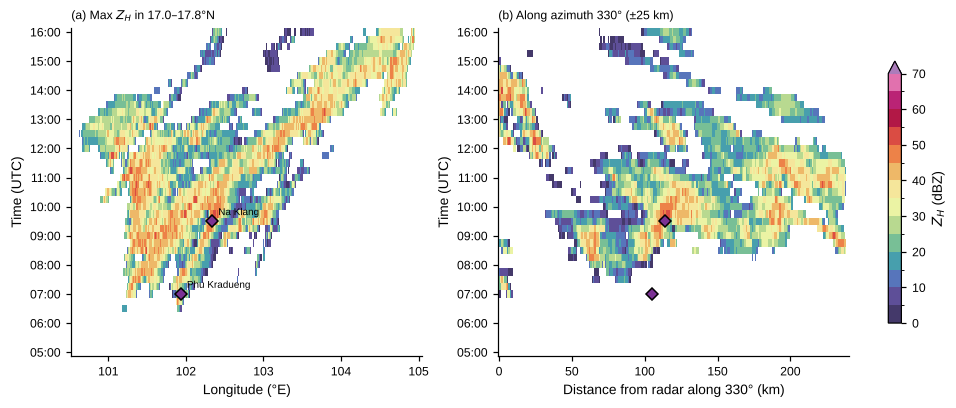

In [6]:
lat_band = (17.0, 17.8)                                   # แถบละติจูดผ่านหนองบัวลำภู–อุดรธานี
rows_band = np.where((meta["lat"][:, 240] >= lat_band[0]) & (meta["lat"][:, 240] <= lat_band[1]))[0]
win = slice(time_index(meta, "05:00"), time_index(meta, "16:00") + 1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    H_lon = np.nanmax(Z[win][:, rows_band, :], axis=1)        # (t, x)
lon_axis = meta["lon"][rows_band[len(rows_band) // 2], :]
d_az, H_az = kt.hovmoller(Z[win], meta, azimuth_deg=330, half_width_km=25)

cmap, norm = mp.refl_cmap_norm()
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.6), layout="constrained")
tt = ts[win]
for ax, xaxis, H, xl, ttl in [(axs[0], lon_axis, H_lon, "Longitude (°E)", f"(a) Max $Z_H$ in {lat_band[0]}–{lat_band[1]}°N"),
                             (axs[1], d_az, H_az, "Distance from radar along 330° (km)", "(b) Along azimuth 330° (±25 km)")]:
    im = ax.pcolormesh(xaxis, tt, np.ma.masked_less(H, 0), cmap=cmap, norm=norm, shading="nearest", rasterized=True)
    ax.set_xlabel(xl)
    ax.set_title(ttl, loc="left", fontsize=8)
    ax.yaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
    ax.set_ylabel("Time (UTC)")
for name in ["Phu Kradueng", "Na Klang"]:
    r = kt.site(reports, name)
    t_rep = kt.report_time_utc(r, date0)
    axs[0].plot(r["lon"], t_rep, marker="D", mfc="#7b3294", mec="k", ms=6)
    axs[0].annotate(name, (r["lon"], t_rep), xytext=(4, 4), textcoords="offset points", fontsize=6.5)
    axs[1].plot(r["range_km"], t_rep, marker="D", mfc="#7b3294", mec="k", ms=6)
fig.colorbar(im, ax=axs, shrink=0.8, extend="max", label="$Z_H$ (dBZ)")
mp.save_figure(fig, "nb3_hovmoller")
plt.show()

**อ่านภาพ (a):** แถบสีที่ "เอียงไปทางขวาเมื่อเวลาผ่านไป" แปลว่ากลุ่มพายุเคลื่อนไปทาง **ตะวันออก**
ความเร็ว ≈ (ระยะที่เลื่อน ÷ เวลา) — ที่ละติจูด 17°N, 1° ลองจิจูด ≈ 106 km
สังเกตด้วยว่า **แถบใหม่เกิดขึ้นทางตะวันออกของแถบเดิม** ในบางช่วง ซึ่งเป็นลักษณะของ propagation (เกิดใหม่ ไม่ใช่ลูกเดิมเคลื่อนไป)

## 🚀 6. Extrapolation nowcast จาก 09:00 UTC (16:00 น.) — 30 นาทีก่อนเหตุที่หนองบัวลำภู

บันทึกรูปแล้ว: figures/nb3_extrapolation_0900.png, figures/nb3_extrapolation_0900.pdf


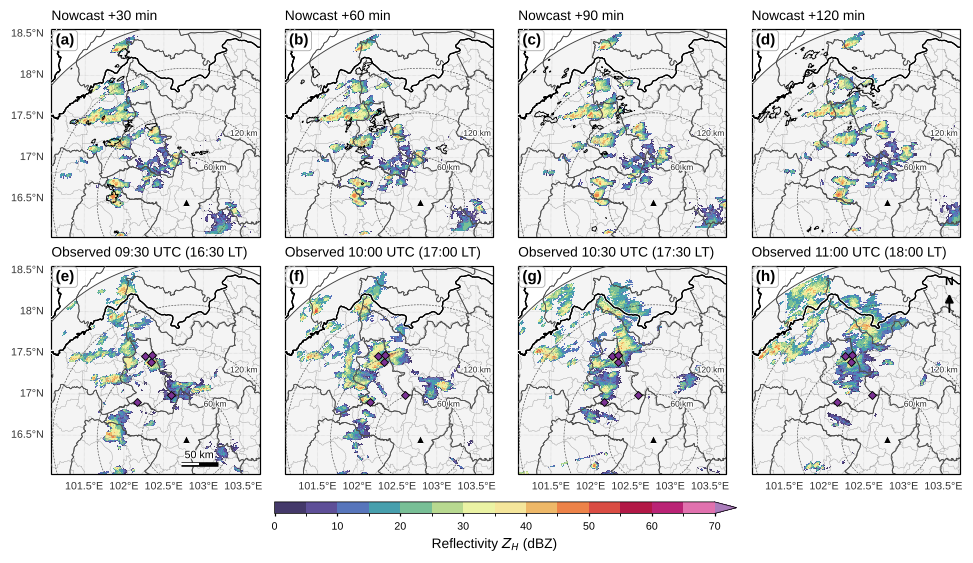

In [7]:
i0 = time_index(meta, "09:00")
V0 = oflow(Xin[i0 - 2:i0 + 1], verbose=False)
n_lead = 8                                              # +15 ถึง +120 นาที
F = extrapolate(Xin[i0], V0, n_lead)
F[F < 0] = np.nan                                       # แสดงเฉพาะ echo
leads = [2, 4, 6, 8]
fig, axs = mp.map_panels(2, 4, mc, panel_width=2.2)
for k, L in enumerate(leads):
    obs = Zc[i0 + L]
    im = mp.radar_map(axs[k], F[L - 1], mc, title=f"Nowcast +{L*DT:.0f} min", scalebar=False, north=False,
                      gridline_labels=("left",) if k == 0 else ())
    mp.obs_contour(axs[k], obs, mc, level=35, color="k", linewidth=0.6)
    mp.radar_map(axs[k + 4], obs, mc, title=f"Observed {mp.tlabel(ts[i0 + L])}", scalebar=(k == 0), north=(k == 3),
                 gridline_labels=(("left",) if k == 0 else ()) + ("bottom",))
    mp.add_reports(axs[k + 4], reports.query("province == 'Nong Bua Lam Phu'"), legend=False, ms=4)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs, shrink=0.5)
mp.save_figure(fig, "nb3_extrapolation_0900")
plt.show()

เส้นดำในแถวบน = ขอบ 35 dBZ ที่ **สังเกตจริง** — ช่วง +30 นาทีตำแหน่งยังใกล้เคียง แต่หลัง +60 นาที **เซลล์ใหม่เกิดขึ้น เซลล์เก่าสลาย** ซึ่ง extrapolation ทำนายไม่ได้

## ⏱️ 7. Advection interpolation 15 → 5 นาที และฝนสะสมที่นากลาง

บันทึกรูปแล้ว: figures/nb3_interpolation.png, figures/nb3_interpolation.pdf


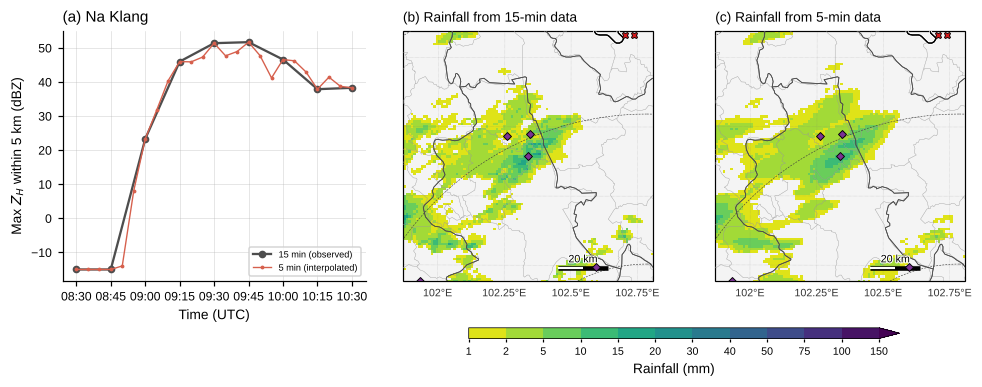

ฝนสะสม 08:30–10:30 UTC ที่นากลาง (เฉลี่ย 5 km): ข้อมูล 15 นาที 9.7 mm | ข้อมูล 5 นาที 9.6 mm


In [8]:
iA, iB = time_index(meta, "08:30"), time_index(meta, "10:30")
meta_c = dict(mc, timestamps=ts[iA:iB + 1])
Z5, ts5, _ = kt.advection_interpolate(Zc[iA:iB + 1], meta_c, n_sub=3)
r = kt.site(reports, "Na Klang")
s15 = kt.point_series(Zc[iA:iB + 1], mc, r["lon"], r["lat"], 5)
s5 = kt.point_series(Z5, mc, r["lon"], r["lat"], 5)
R15 = kt.dbz_to_rainrate(Zc[iA:iB + 1], 200, 1.6)
R5 = kt.dbz_to_rainrate(Z5, 200, 1.6)
P15, P5 = kt.accumulate(R15[:-1], 15), kt.accumulate(R5[:-1], 5)
p15 = kt.point_series(P15[None], mc, r["lon"], r["lat"], 5, "mean")[0]
p5 = kt.point_series(P5[None], mc, r["lon"], r["lat"], 5, "mean")[0]

fig = plt.figure(figsize=(9, 3.4), layout="constrained")
ax = fig.add_subplot(1, 3, 1)
ax.plot(ts[iA:iB + 1], s15, "o-", color="0.3", ms=4, label="15 min (observed)")
ax.plot(ts5, s5, ".-", color="#d6604d", ms=3, lw=0.9, label="5 min (interpolated)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
mp.skill_axes(ax, xlabel="Time (UTC)", ylabel="Max $Z_H$ within 5 km (dBZ)", title="(a) Na Klang")
ax.legend(fontsize=6)
for k, (P, lab) in enumerate([(P15, "(b) Rainfall from 15-min data"), (P5, "(c) Rainfall from 5-min data")]):
    axm = fig.add_subplot(1, 3, k + 2, projection=mp.get_crs(mc))
    zoom = kt.box_around(mc, r["lon"], r["lat"], 50)
    im = mp.radar_map(axm, P, mc, units="mm", ptype="depth", zoom=zoom, title=lab, north=False,
                      gridline_labels=("bottom",))
    mp.add_reports(axm, reports, legend=False, ms=4)
mp.add_colorbar(fig, im, fig.axes[1:], shrink=0.7)
mp.save_figure(fig, "nb3_interpolation")
plt.show()
print(f"ฝนสะสม 08:30–10:30 UTC ที่นากลาง (เฉลี่ย 5 km): ข้อมูล 15 นาที {p15:.1f} mm | ข้อมูล 5 นาที {p5:.1f} mm")

ข้อมูลทุก 15 นาทีทำให้ฝนสะสมเป็น **"ลาย" ตามตำแหน่งที่พายุอยู่ตอนสแกน** (ภาพ b) การ interpolate ทำให้ฝนกระจายตามเส้นทางจริงต่อเนื่องขึ้น (ภาพ c)

## 🌀 8. (เสริม) Doppler และ spectrum width: ลมในพายุหนองบัวลำภู
ไฟล์ polar ขนาดเล็กใน `data/polar/` (09:15–09:45 UTC) มีความเร็ว Doppler **ที่ยังไม่แก้ aliasing** และ spectrum width ที่มุมยก 0.48°
- **Doppler velocity $V_r$** = ความเร็วของเม็ดฝน **ตามแนวลำคลื่น** (+ = เคลื่อนออกจากเรดาร์, − = เข้าหาเรดาร์) — วัดได้เพียงช่วง **±$V_{Nyq}$** (KKN วันนั้น = **8.38 m/s**) ถ้าลมแรงกว่านั้นค่าจะ "พับ" (aliasing) กลับมาเป็นสีตรงข้าม
- **Spectrum width $\sigma_v$** = ความกระจายของความเร็วในลำคลื่น สูงเมื่อมี **ความปั่นป่วน / ลมเฉือนแรง** (เช่น บริเวณ gust front)
- motion field จาก NB3 = การเคลื่อนที่ของ **รูปแบบฝน** ส่วน Doppler = **ลมจริง** ในพายุ (รวม outflow) — สองอย่างนี้ไม่เหมือนกัน!

In [9]:
import glob
polar_files = sorted(glob.glob(os.path.join(DATA, "polar", "KKN_20240503_*_polar.nc")))
if not polar_files:
    print("ℹ️ ยังไม่มีไฟล์ใน data/polar/ — ข้ามส่วนนี้ได้\n"
          "   ผู้สอนสร้างได้จาก notebook 00_prepare_polar_for_doppler_pytda_hid (repo ที่ 2) โดยตั้ง\n"
          "   REPO2_TIMES = ['20240503_0915', '20240503_0930', '20240503_0945'] แล้วคัดลอก 3 ไฟล์มาไว้ที่ data/polar/")
else:
    from utils.data_io import load_polar
    nb_zoom = kt.box_around(meta, 102.3, 17.35, 60)
    try:
        _r0 = load_polar(polar_files[0])
        vny = float(np.nanmedian(_r0.instrument_parameters["nyquist_velocity"]["data"]))
    except Exception:
        vny = 8.38                                       # ค่าของ KKN วันที่ 3 พ.ค. 2567
    vcmap = plt.matplotlib.colormaps["RdBu_r"]
    vnorm = plt.matplotlib.colors.BoundaryNorm(np.linspace(-vny, vny, 13), vcmap.N)
    swcmap, swnorm = plt.matplotlib.colormaps["cividis"], plt.matplotlib.colors.BoundaryNorm(np.arange(0, 9, 1), 256)
    zcmap, znorm = mp.refl_cmap_norm()
    nrow = len(polar_files)
    fig = plt.figure(figsize=(8.4, 2.8 * nrow), layout="constrained")
    for k, f in enumerate(polar_files):
        rad = load_polar(f)
        tag = os.path.basename(f).split("_")[2]
        panels = [("reflectivity_qc", zcmap, znorm, "$Z_H$"), ("velocity_qc", vcmap, vnorm, "$V_r$ (aliased)"),
                  ("spectrum_width_qc", swcmap, swnorm, "$\\sigma_v$")]
        for j, (fld, cm, nm, lab) in enumerate(panels):
            ax = fig.add_subplot(nrow, 3, 3 * k + j + 1, projection=mp.get_crs(meta))
            if fld not in rad.fields:
                ax.set_visible(False)
                continue
            q = mp.plot_ppi(ax, rad, fld, 0, meta, cm, nm, zoom=nb_zoom)
            mp.add_basemap(ax, meta, labels=("left",) if j == 0 else ())
            mp.add_reports(ax, reports, legend=False, ms=4)
            ax.set_title(f"{lab}, {tag[:2]}:{tag[2:]} UTC, 0.48°", loc="left", fontsize=7)
            if k == nrow - 1:
                fig.colorbar(q, ax=ax, orientation="horizontal", shrink=0.85, pad=0.03,
                             ticks=[-8, -4, 0, 4, 8] if "V_r" in lab else None,
                             label={"$Z_H$": "dBZ", "$V_r$ (aliased)": "m s$^{-1}$", "$\\sigma_v$": "m s$^{-1}$"}[lab])
    mp.save_figure(fig, "nb3_doppler_nongbualamphu")
    plt.show()
    print(f"Nyquist velocity = {vny:.2f} m/s: ลมกระโชกจาก downburst (20–30 m/s) จะพับ (alias) 1–2 รอบ — สังเกตจุดที่สีแดง/น้ำเงินเข้มอยู่ติดกัน")

ℹ️ ยังไม่มีไฟล์ใน data/polar/ — ข้ามส่วนนี้ได้
   ผู้สอนสร้างได้จาก notebook 00_prepare_polar_for_doppler_pytda_hid (repo ที่ 2) โดยตั้ง
   REPO2_TIMES = ['20240503_0915', '20240503_0930', '20240503_0945'] แล้วคัดลอก 3 ไฟล์มาไว้ที่ data/polar/


---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 3.1: ความเร็วและทิศทางของพายุตลอดบ่าย
คำนวณ motion field ด้วย **LK** ทุกเวลาตั้งแต่ **05:30 ถึง 14:00 UTC** (ใช้ 3 ภาพก่อนหน้าทุกครั้ง) แล้วหา **ความเร็วมัธยฐาน (km/h)** และ **ทิศที่ไป** ในบริเวณพายุ (≥ 35 dBZ) พล็อตกราฟความเร็ว และทิศ กับเวลา

**คำถาม:** ความเร็วเปลี่ยนไปอย่างไรระหว่างช่วงก่อตัว ช่วงสูงสุด และช่วงรวมตัว? ช่วงใดที่ทิศทางแปรปรวนมากที่สุด และทำไม?

<details>
<summary><b>💡 คำใบ้ (คลิกเพื่อเปิด)</b></summary>

- `for i in range(time_index(meta, "05:30"), time_index(meta, "14:00") + 1):`
- ข้ามเวลาที่ไม่มีข้อมูลครบ: `if not meta["available"][i - 2:i + 1].all(): continue`
- `V = oflow(Xin[i - 2:i + 1], verbose=False)` แล้ว `kt.speed_dir(V, storm(i))`

</details>

In [10]:
# ✍️ แบบฝึกหัด 3.1 — เขียนโค้ดของคุณที่นี่ (ลบ # หน้าบรรทัดแล้วเติมส่วนที่เป็น ...)
# rows = []
# for i in range(time_index(meta, "05:30"), time_index(meta, "14:00") + 1):
#     if not meta["available"][i - 2:i + 1].all():
#         continue
#     V = oflow(Xin[i - 2:i + 1], verbose=False)
#     ...

บันทึกรูปแล้ว: figures/nb3_ex31_speed_direction.png, figures/nb3_ex31_speed_direction.pdf


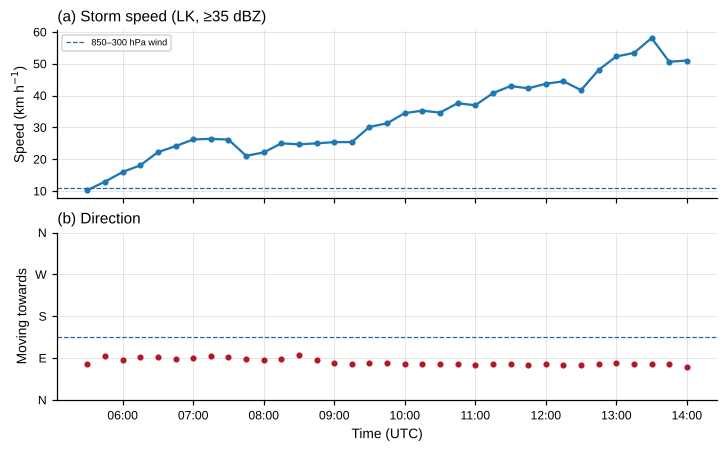

 time  speed_kmh  dir_to_deg
05:30       10.0        78.0
05:45       13.0        93.0
06:00       16.0        85.0
06:15       18.0        91.0
06:30       22.0        92.0
06:45       24.0        88.0
07:00       26.0        91.0
07:15       26.0        95.0
07:30       26.0        93.0
07:45       21.0        88.0
08:00       22.0        86.0
08:15       25.0        89.0
08:30       25.0        97.0
08:45       25.0        86.0
09:00       25.0        80.0
09:15       25.0        77.0
09:30       30.0        78.0
09:45       31.0        78.0
10:00       34.0        78.0
10:15       35.0        77.0
10:30       35.0        78.0
10:45       38.0        77.0
11:00       37.0        76.0
11:15       41.0        77.0
11:30       43.0        77.0
11:45       42.0        76.0
12:00       44.0        76.0
12:15       44.0        75.0
12:30       42.0        74.0
12:45       48.0        78.0
13:00       52.0        78.0
13:15       53.0        77.0
13:30       58.0        76.0
13:45       51

In [11]:
#@title ✅ เฉลยแบบฝึกหัด 3.1 (ลองทำเองก่อน! ดับเบิลคลิกเพื่อดูโค้ด แล้วกด ▶ เพื่อรัน)
rows = []
for i in range(time_index(meta, "05:30"), time_index(meta, "14:00") + 1):
    if not meta["available"][i - 2:i + 1].all() or storm(i).sum() < 20:
        continue
    V = oflow(Xin[i - 2:i + 1], verbose=False)
    spd, ang = kt.speed_dir(V, storm(i))
    rows.append({"time": ts[i], "speed_kmh": spd, "dir_to_deg": ang})
mv = pd.DataFrame(rows)
fig, axs = plt.subplots(2, 1, figsize=(6.5, 4), sharex=True, layout="constrained")
axs[0].plot(mv["time"], mv["speed_kmh"], "o-", color="#1f77b4", ms=3)
axs[0].axhline(spd_env * 3.6, color="#2166ac", ls="--", lw=0.8, label="850–300 hPa wind")
axs[0].legend(fontsize=6)
mp.skill_axes(axs[0], xlabel="", ylabel="Speed (km h$^{-1}$)", title="(a) Storm speed (LK, ≥35 dBZ)")
axs[1].plot(mv["time"], mv["dir_to_deg"], "o", color="#b2182b", ms=3)
axs[1].axhline(dir_env, color="#2166ac", ls="--", lw=0.8)
axs[1].set_yticks([0, 90, 180, 270, 360])
axs[1].set_yticklabels(["N", "E", "S", "W", "N"])
mp.skill_axes(axs[1], xlabel="Time (UTC)", ylabel="Moving towards", title="(b) Direction")
mp.time_axis(axs[1], local_top=False, interval_h=1)
mp.save_figure(fig, "nb3_ex31_speed_direction")
plt.show()
print(mv.assign(time=mv["time"].dt.strftime("%H:%M")).round(0).to_string(index=False))

### 🧪 แบบฝึกหัด 3.2: propagation มีบทบาทแค่ไหนในแต่ละช่วง?
ทำซ้ำการคำนวณในหัวข้อ 4 (เวกเตอร์ propagation = การเคลื่อนที่ของพายุ − ลม 850–300 hPa) ที่เวลา **06:45, 09:15, 11:00, 13:00 UTC** แล้วสร้างตาราง: ขนาดของ $\mathbf{V}_{\mathrm{system}}$, $\mathbf{V}_{\mathrm{propagation}}$ และอัตราส่วน $|\mathbf{V}_{\mathrm{prop}}|/|\mathbf{V}_{\mathrm{system}}|$

**คำถาม:** ถ้าอัตราส่วนใกล้ 1 หมายความว่าอย่างไร? ข้อนี้บอกอะไรเกี่ยวกับความน่าเชื่อถือของ extrapolation nowcast ในเคสนี้?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ใช้โค้ดในหัวข้อ 4: `u_sys = np.mean(V[0][m]) * 1000 / (DT * 60)` และ `v_sys = -np.mean(V[1][m]) * 1000 / (DT * 60)`
- `u_env, v_env` คำนวณไว้แล้ว

</details>

In [12]:
# ✍️ แบบฝึกหัด 3.2 — เขียนโค้ดของคุณที่นี่

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 3.2
rows = []
for hh in ["06:45", "09:15", "11:00", "13:00"]:
    i = time_index(meta, hh)
    V = oflow(Xin[i - 2:i + 1], verbose=False)
    m = storm(i)
    us, vs = np.mean(V[0][m]) * 1000 / (DT * 60), -np.mean(V[1][m]) * 1000 / (DT * 60)
    up, vp = us - u_env, vs - v_env
    rows.append({"time": mp.tlabel(ts[i]), "|V_system| m/s": np.hypot(us, vs),
                 "system_dir": kt.compass(np.degrees(np.arctan2(us, vs))),
                 "|V_prop| m/s": np.hypot(up, vp), "prop_dir": kt.compass(np.degrees(np.arctan2(up, vp))),
                 "ratio": np.hypot(up, vp) / np.hypot(us, vs)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\n→ อัตราส่วนใกล้ 1 = การเคลื่อนที่เกือบทั้งหมดมาจาก propagation (เซลล์ใหม่) ไม่ใช่ลมพัดพา และเพิ่มขึ้นเมื่อระบบรวมตัวตอนค่ำ"
      "\n  extrapolation เลื่อนรูปแบบเดิมด้วยความเร็วล่าสุด จึงพลาดเมื่อเซลล์ใหม่เกิดหรือความเร็วเปลี่ยน")

                time  |V_system| m/s system_dir  |V_prop| m/s prop_dir  ratio
06:45 UTC (13:45 LT)            6.63          E          5.12      ENE   0.77
09:15 UTC (16:15 LT)            7.32        ENE          6.33       NE   0.86
11:00 UTC (18:00 LT)           10.23        ENE          9.13      ENE   0.89
13:00 UTC (20:00 LT)           14.03        ENE         12.68      ENE   0.90

→ อัตราส่วนใกล้ 1 = การเคลื่อนที่เกือบทั้งหมดมาจาก propagation (เซลล์ใหม่) ไม่ใช่ลมพัดพา และเพิ่มขึ้นเมื่อระบบรวมตัวตอนค่ำ
  extrapolation เลื่อนรูปแบบเดิมด้วยความเร็วล่าสุด จึงพลาดเมื่อเซลล์ใหม่เกิดหรือความเร็วเปลี่ยน


### 🧪 แบบฝึกหัด 3.3: interpolate ละเอียดแค่ไหนจึงพอ?
ใช้ `kt.advection_interpolate` กับข้อมูล 08:30–10:30 UTC ด้วย `n_sub` = 1 (ไม่ interpolate), 3 (5 นาที) และ 5 (3 นาที) แล้วคำนวณ **ฝนสะสมสูงสุดในกรอบ 50 km รอบนากลาง** และ **ค่าเฉลี่ยรอบนากลาง** ของแต่ละกรณี

**คำถาม:** ค่าเปลี่ยนมากระหว่าง 15 → 5 นาที แต่น้อยลงระหว่าง 5 → 3 นาทีหรือไม่? ถ้าเรดาร์สแกนทุก 5 นาทีจริงจะดีกว่า interpolation อย่างไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `Zi, tsi, _ = kt.advection_interpolate(Zc[iA:iB + 1], meta_c, n_sub=n)` (สำหรับ `n = 1` ใช้ `Zc[iA:iB + 1]` ได้เลย)
- ช่วงเวลาของแต่ละภาพ = `15 / n` นาที → `kt.accumulate(R[:-1], 15 / n)`
- กรอบรอบนากลาง: `Pz, mz = kt.crop(P[None], mc, kt.box_around(mc, r["lon"], r["lat"], 50))`

</details>

In [14]:
# ✍️ แบบฝึกหัด 3.3 — เขียนโค้ดของคุณที่นี่

In [15]:
#@title ✅ เฉลยแบบฝึกหัด 3.3
rows = []
for n in [1, 3, 5]:
    Zi = Zc[iA:iB + 1] if n == 1 else kt.advection_interpolate(Zc[iA:iB + 1], meta_c, n_sub=n)[0]
    P = kt.accumulate(kt.dbz_to_rainrate(Zi[:-1], 200, 1.6), 15 / n)
    Pz, _ = kt.crop(P[None], mc, kt.box_around(mc, r["lon"], r["lat"], 50))
    rows.append({"time_step_min": 15 / n, "max_in_box_mm": np.nanmax(Pz),
                 "Na_Klang_mean_mm": kt.point_series(P[None], mc, r["lon"], r["lat"], 5, "mean")[0]})
print(pd.DataFrame(rows).round(1).to_string(index=False))
print("\n→ ค่าสูงสุดลดลงและฝนกระจายต่อเนื่องขึ้นเมื่อ interpolate (ลด 'ลาย' จากการสุ่มทุก 15 นาที)"
      "\n  แต่ interpolation สร้างเซลล์ใหม่หรือการเปลี่ยนความแรงระหว่างสแกนไม่ได้ — การสแกนถี่จริงจึงดีกว่าเสมอ")

 time_step_min  max_in_box_mm  Na_Klang_mean_mm
          15.0           21.3               9.7
           5.0           13.9               9.6
           3.0           13.2               9.4

→ ค่าสูงสุดลดลงและฝนกระจายต่อเนื่องขึ้นเมื่อ interpolate (ลด 'ลาย' จากการสุ่มทุก 15 นาที)
  แต่ interpolation สร้างเซลล์ใหม่หรือการเปลี่ยนความแรงระหว่างสแกนไม่ได้ — การสแกนถี่จริงจึงดีกว่าเสมอ


---
## 📝 สรุป
- LK, VET และ DARTS ให้ทิศทางใกล้เคียงกัน: กลุ่มพายุเคลื่อนไปทาง **ตะวันออก–ตะวันออกเฉียงเหนือ** และ **เร่งความเร็ว** จาก ~10 km/h ช่วงก่อตัว → ~25 km/h ช่วงบ่าย → 40–55 km/h ตอนค่ำ
- ลม 850–300 hPa จาก sounding **อ่อน (~11 km/h) และพัดไปทางตะวันออกเฉียงใต้** → การเคลื่อนที่ 77–90% มาจาก **propagation** (เซลล์ใหม่เกิดตามแนว outflow) และยิ่งมากขึ้นเมื่อระบบรวมตัว
- **Hovmöller diagram** แสดงทั้งการเคลื่อนที่และการเกิดใหม่ของกลุ่มพายุในภาพเดียว
- extrapolation ตำแหน่งยังใกล้เคียงที่ +30 นาที แต่หลังจากนั้นการเกิด/สลายของเซลล์ครอบงำ (จะวัดด้วยคะแนน verification ใน NB4)
- advection interpolation 15 → 5 นาทีช่วยให้ฝนสะสมสมจริงขึ้น แต่ไม่ได้แทนการสแกนที่ถี่ขึ้น

### ❓ คำถามชวนคิด
1. ถ้าเลือก motion field จาก "ลม" ใน sounding แทน optical flow จะได้ nowcast ที่ดีขึ้นหรือแย่ลง? เพราะอะไร?
2. ทำไมกลุ่มพายุจึง **เร่งความเร็วขึ้นเรื่อย ๆ ตอนค่ำ** ทั้งที่ลมแทบไม่เปลี่ยน? (คิดถึง cold pool ที่ใหญ่และแรงขึ้นเมื่อเซลล์รวมตัว)
3. Doppler velocity บอกอะไรที่ optical flow บอกไม่ได้? ทำไม Nyquist velocity 8.38 m/s จึงเป็นปัญหาสำหรับการศึกษาลมกระโชกแรง?

**🚀 ต่อยอด:** ลองทำ Hovmöller ตามแนวรัศมีอื่น (เช่น 300° ไปภูกระดึง หรือ 20° ไปบึงกาฬ) แล้วเทียบความเร็วกับผลจาก LK

### 📚 เอกสารอ้างอิง
- Bowler, N. E., Pierce, C. E., & Seed, A. (2004). Development of a precipitation nowcasting algorithm based upon optical flow techniques. *J. Hydrol.*, 288, 74–91.
- Corfidi, S. F. (2003). Cold pools and MCS propagation: Forecasting the motion of downwind-developing MCSs. *Wea. Forecasting*, 18, 997–1017.
- Laroche, S., & Zawadzki, I. (1995). Retrievals of horizontal winds from single-Doppler clear-air data by methods of cross correlation and variational analysis. *J. Atmos. Oceanic Technol.*, 12, 721–738.
- Ruzanski, E., Chandrasekar, V., & Wang, Y. (2011). The CASA nowcasting system. *J. Atmos. Oceanic Technol.*, 28, 640–655.
- Pulkkinen, S., et al. (2019). Pysteps v1.0. *Geosci. Model Dev.*, 12, 4185–4219.